# Car price prediction – and why no model beats the mean

**Task:** regression – predict `Price_USD` of a car from brand, year, mileage, fuel, transmission, engine and other attributes.
**Data:** [Car Price Prediction Dataset (Kaggle)](https://www.kaggle.com/datasets/prince7489/car-price-prediction-dataset) – 1,000 rows, 12 columns, no missing values.
**Methods:** scikit-learn pipelines, feature engineering (`Car_Age`, `Km_per_Year`, `Power_per_CC`), 7 regression models, 10-fold CV, `GridSearchCV`, correlation / mutual-information diagnostics and a **label-shuffling test**.

**Key finding:** none of the models – from Linear Regression to Gradient Boosting, tuned or not – is reliably better than *always predicting the mean price*: cross-validated R² is ≤ 0 for every model and the best test R² is only +0.01 (within noise). Diagnostics show why: the numeric features have no meaningful relationship with the price (all |r| < 0.08), the categories do not separate prices (one weak nominal exception that does not survive multiple-testing correction), and a model trained on a *shuffled* price scores just as badly as one trained on the real price. The dataset appears to be synthetic with a randomly generated price, so the honest result of this project is *"there is (almost) nothing to learn here"*, backed by evidence.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore", message=".*vert.*")

from scipy import stats
from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.feature_selection import mutual_info_regression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 42
import os; os.makedirs("figures", exist_ok=True)

## 1. Load the data

In [2]:
df = pd.read_csv("car_price_dataset_medium.csv")   # download from Kaggle (link above)
TARGET = "Price_USD"
print("Shape:", df.shape, "| missing values:", int(df.isna().sum().sum()))
df.head()

Shape: (1000, 12) | missing values: 0


,Car_ID,Brand,Model_Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Engine_CC,Max_Power_bhp,Mileage_kmpl,Seats,Price_USD
0,1,Audi,2005,197018,Diesel,Manual,First,4046,223.6,29.61,6,119611.94
1,2,BMW,2019,43467,Hybrid,Automatic,First,3731,248.4,21.66,5,90842.46
2,3,Kia,2012,153697,Hybrid,Automatic,Third,4925,465.5,12.14,6,78432.24
3,4,Mercedes,2015,38893,Petrol,Automatic,Second,3771,229.7,19.65,6,44568.89
4,5,Audi,2016,81329,Hybrid,Automatic,First,2817,573.2,7.74,5,8751.82


## 2. Exploratory data analysis
`Car_ID` is only a row identifier and is excluded from modelling.

In [3]:
num_eda = [c for c in df.select_dtypes("number").columns if c != "Car_ID"]
print(df[num_eda].describe().T.round(2))
print("\nSkewness:"); print(df[num_eda].skew().round(3).sort_values(ascending=False))

                    count       mean       std      min       25%        50%  \
Model_Year         1000.0    2014.49      5.71  2005.00   2009.75    2015.00   
Kilometers_Driven  1000.0  103397.07  57417.61  5155.00  52188.50  102449.00   
Engine_CC          1000.0    2878.30   1212.34   801.00   1818.25    2857.50   
Max_Power_bhp      1000.0     320.94    160.38    40.50    184.82     314.65   
Mileage_kmpl       1000.0      17.34      7.30     5.04     10.97      17.14   
Seats              1000.0       4.66      1.80     2.00      4.00       5.00   
Price_USD          1000.0   59217.25  33545.25  3028.42  30030.82   56806.74   

                         75%        max  
Model_Year           2019.00    2024.00  
Kilometers_Driven  152696.50  199812.00  
Engine_CC            3959.50    4996.00  
Max_Power_bhp         455.30     599.60  
Mileage_kmpl           24.04      29.99  
Seats                   6.00       7.00  
Price_USD           87088.90  119611.94  

Skewness:
Price_USD   

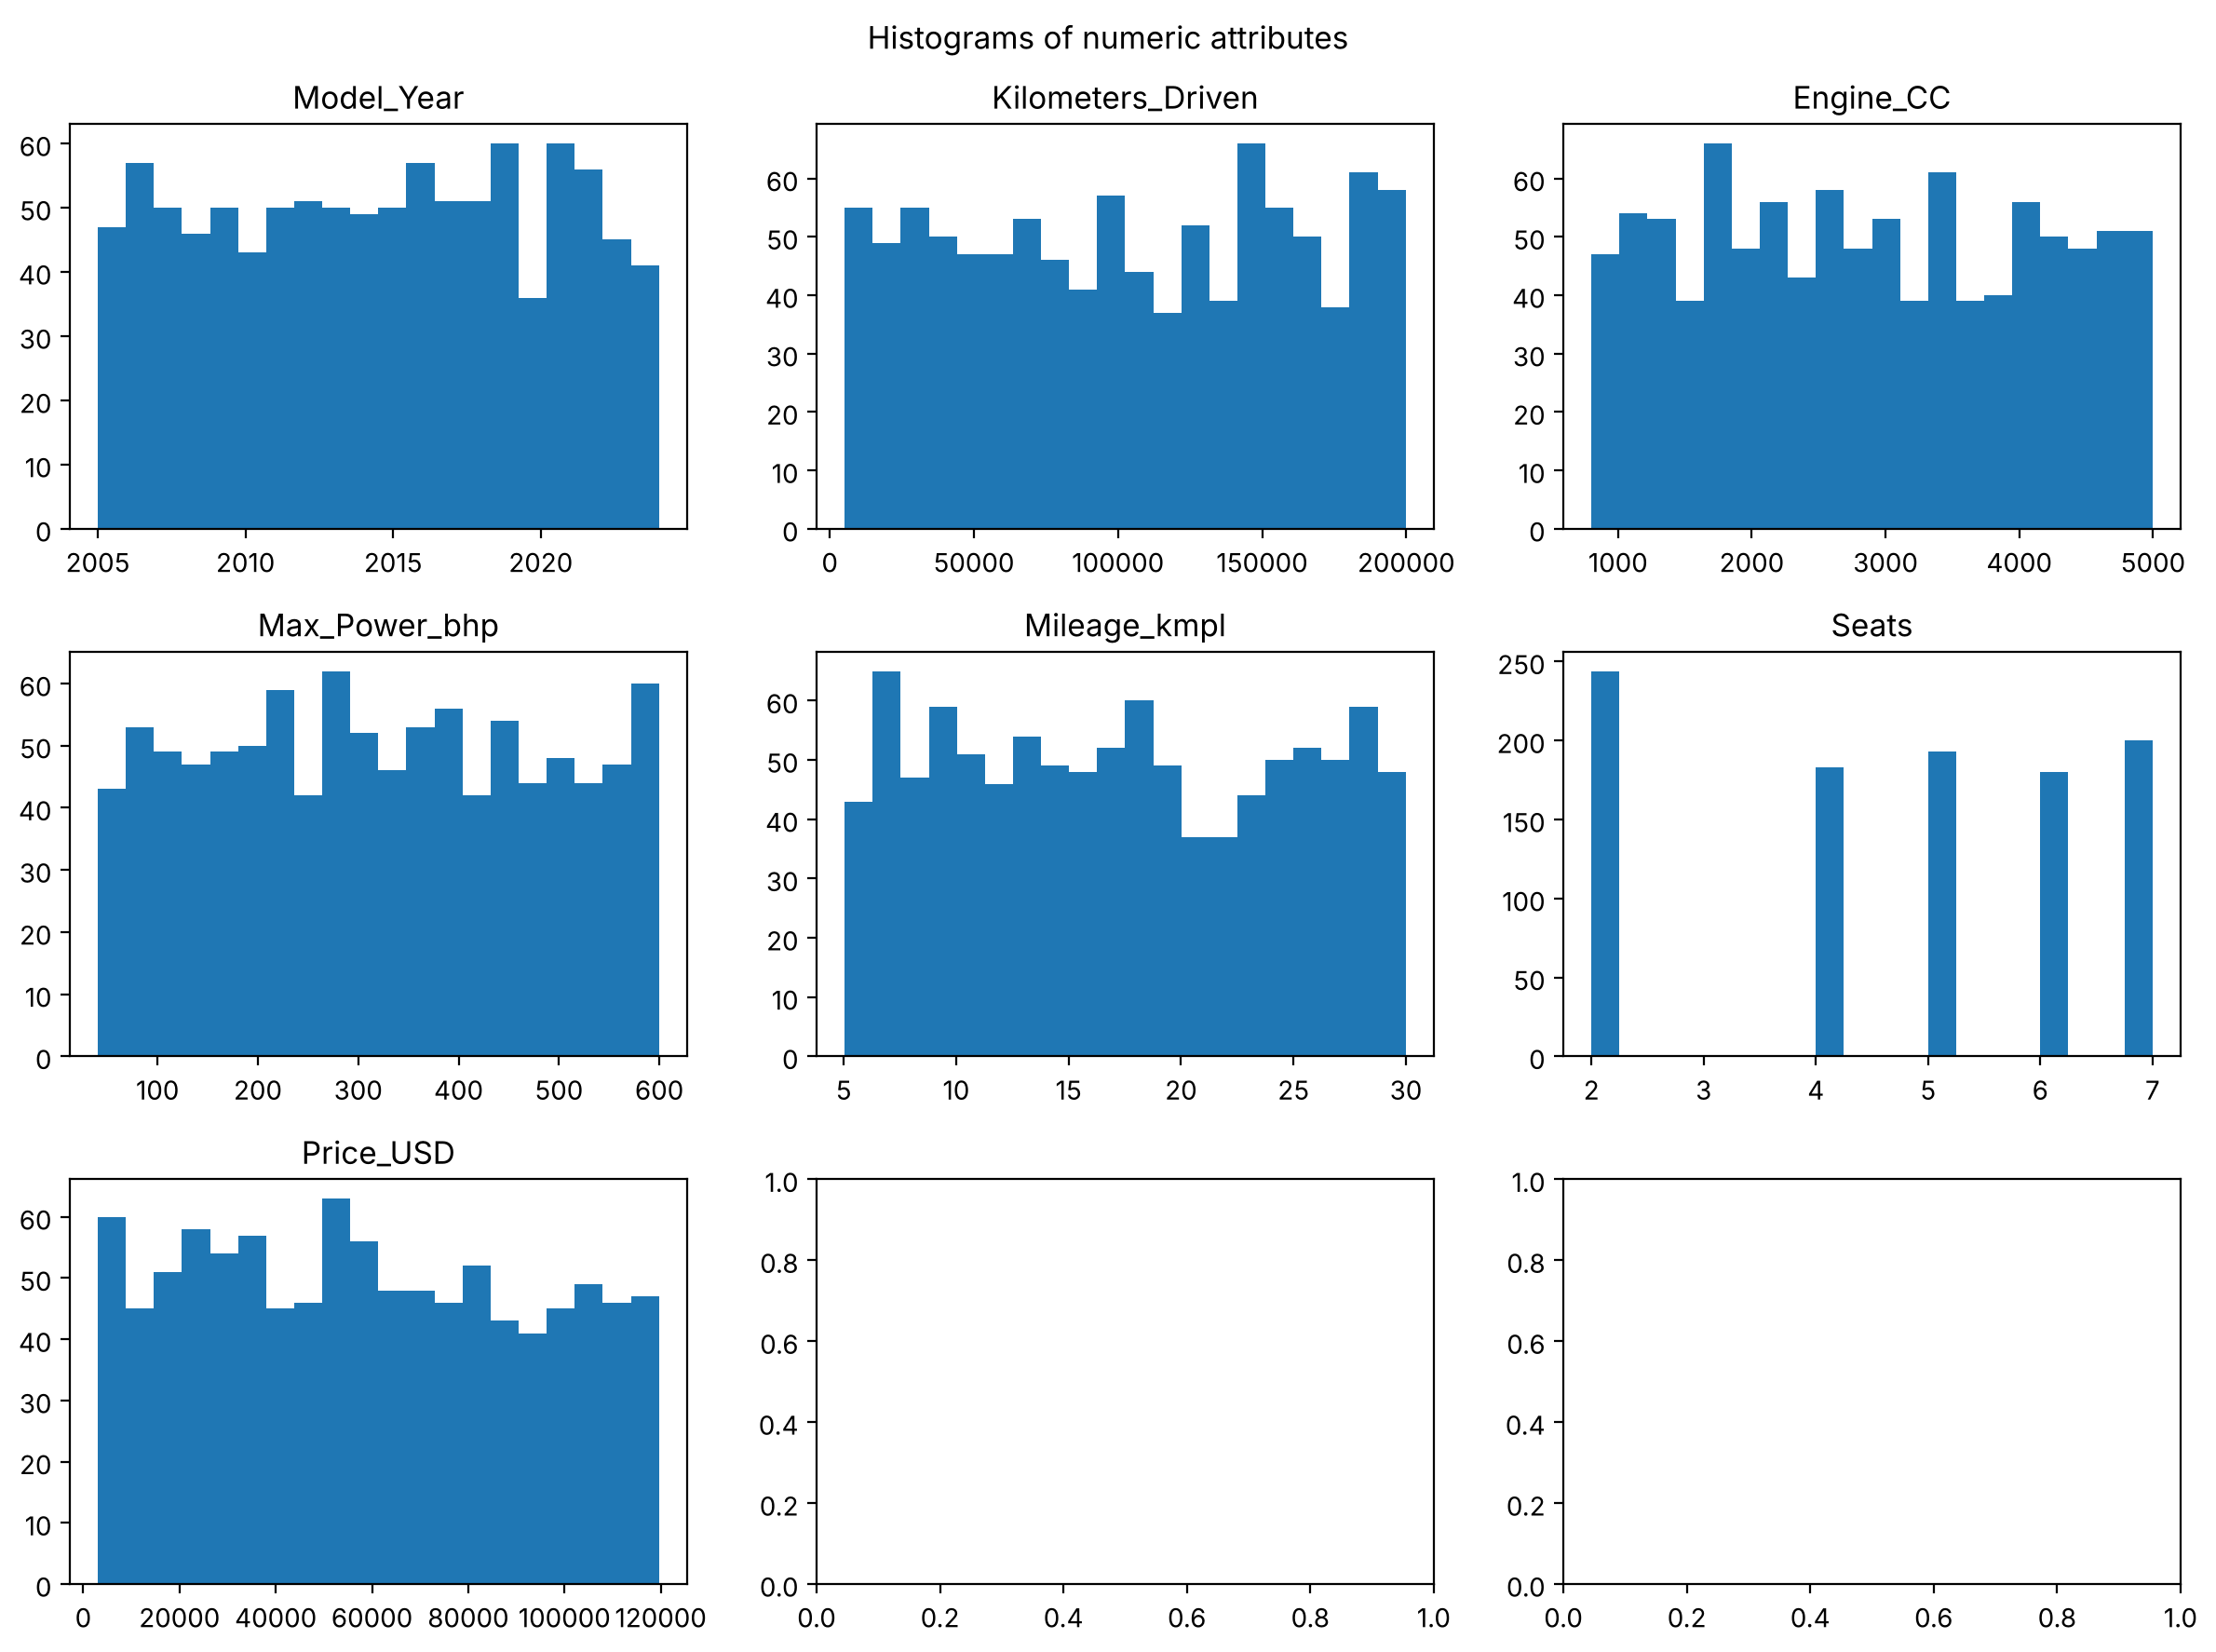

In [4]:
fig, axes = plt.subplots(3, 3, figsize=(12, 9))
for ax, c in zip(axes.ravel(), num_eda):
    ax.hist(df[c], bins=20); ax.set_title(c)
plt.suptitle("Histograms of numeric attributes"); plt.tight_layout()
plt.savefig("figures/histograms.png", dpi=200); plt.show()

All numeric attributes look **uniformly distributed**: skewness is ≈ 0 and the quartiles sit evenly across the range (e.g. `Kilometers_Driven` 52k / 102k / 153k between 5k and 200k; `Price_USD` 30k / 57k / 87k between 3k and 120k). This is typical of randomly generated data – real used-car prices and mileages have a long right tail.

## 3. Feature engineering
Three derived attributes (as in the original assignment). `Car_Age` is an exact linear function of `Model_Year`, so it adds no new information for tree models; `Km_per_Year` and `Power_per_CC` are ratios.

In [5]:
current_year = int(df["Model_Year"].max())
df["Car_Age"] = current_year - df["Model_Year"]
df["Km_per_Year"] = (df["Kilometers_Driven"] / df["Car_Age"].replace(0, np.nan)).fillna(df["Kilometers_Driven"])
df["Power_per_CC"] = df["Max_Power_bhp"] / df["Engine_CC"]
df[["Model_Year", "Car_Age", "Kilometers_Driven", "Km_per_Year", "Max_Power_bhp", "Engine_CC", "Power_per_CC"]].head()

,Model_Year,Car_Age,Kilometers_Driven,Km_per_Year,Max_Power_bhp,Engine_CC,Power_per_CC
0,2005,19,197018,10369.368421,223.6,4046,0.055264
1,2019,5,43467,8693.400000,248.4,3731,0.066577
2,2012,12,153697,12808.083333,465.5,4925,0.094518
3,2015,9,38893,4321.444444,229.7,3771,0.060912
4,2016,8,81329,10166.125000,573.2,2817,0.203479


## 4. Does *any* feature relate to the price?

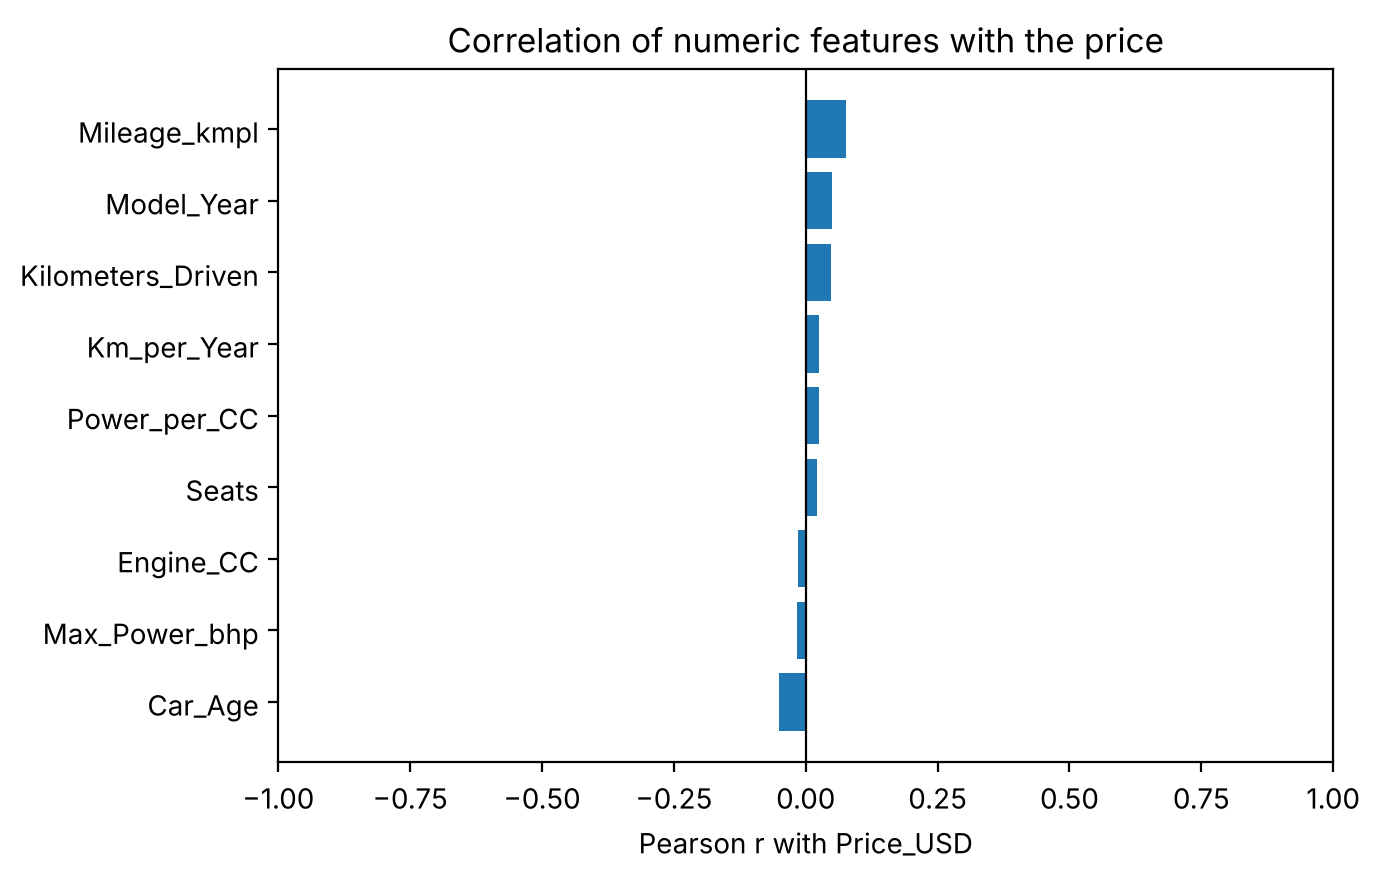

Largest |r|: 0.076


,feature,categories,H,p_value
0,Brand,10,9.71,0.374
1,Fuel_Type,4,0.91,0.823
2,Transmission,2,0.08,0.773
3,Owner_Type,3,8.76,0.013


Mutual information with the price (top 5):
Kilometers_Driven    0.0339
Power_per_CC         0.0326
Model_Year           0.0262
Car_Age              0.0227
Fuel_Type_Diesel     0.0206
dtype: float64


In [6]:
num_feats = [c for c in df.select_dtypes("number").columns if c not in (TARGET, "Car_ID")]
cat_feats = df.select_dtypes(exclude="number").columns.tolist()

corr_t = df[num_feats + [TARGET]].corr()[TARGET].drop(TARGET).sort_values()
plt.figure(figsize=(7, 4.5)); plt.barh(corr_t.index, corr_t.values)
plt.axvline(0, color="k", lw=.8); plt.xlim(-1, 1); plt.xlabel("Pearson r with Price_USD")
plt.title("Correlation of numeric features with the price"); plt.tight_layout()
plt.savefig("figures/corr_with_price.png", dpi=200); plt.show()
print("Largest |r|:", round(corr_t.abs().max(), 3))

# Do the price distributions differ between categories? (Kruskal-Wallis test)
rows = []
for c in cat_feats:
    groups = [g[TARGET].values for _, g in df.groupby(c)]
    h, p = stats.kruskal(*groups)
    rows.append({"feature": c, "categories": len(groups), "H": round(h, 2), "p_value": round(p, 3)})
display(pd.DataFrame(rows))

# Mutual information (captures non-linear dependence too)
X_mi = pd.get_dummies(df[num_feats + cat_feats], columns=cat_feats)
mi = pd.Series(mutual_info_regression(X_mi, df[TARGET], random_state=SEED), index=X_mi.columns).sort_values(ascending=False)
print("Mutual information with the price (top 5):"); print(mi.head(5).round(4))

**Result:** all correlations are tiny (|r| < 0.08). Three of four categorical features show no price differences at all (p = 0.37, 0.82, 0.77); `Owner_Type` has p = 0.013, which is nominally below 0.05 but does not survive a Bonferroni correction for four tests (threshold 0.0125) and, as the models below show, is too weak to improve any prediction. Mutual information values are small (≤ 0.034), at the level of estimator noise. There is essentially no usable signal in the inputs.

## 5. Models
67 / 33 train–test split (as in the original assignment), preprocessing inside a `Pipeline` (standard scaling + one-hot encoding), 10-fold CV on the training set. The **baseline** always predicts the mean training price.

In [7]:
X = df.drop(columns=[TARGET, "Car_ID"]); y = df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=SEED)
print("Train:", X_train.shape, "| Test:", X_test.shape)

num_cols = X.select_dtypes("number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()
preprocess = ColumnTransformer([("num", StandardScaler(), num_cols),
                                ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)])
cv = KFold(n_splits=10, shuffle=True, random_state=SEED)

def evaluate(name, model):
    pipe = Pipeline([("prep", preprocess), ("model", model)])
    cv_r2 = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="r2")
    pipe.fit(X_train, y_train); pred = pipe.predict(X_test)
    return {"Model": name, "MAE": mean_absolute_error(y_test, pred), "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
            "R2_test": r2_score(y_test, pred), "CV_R2_mean": cv_r2.mean(), "CV_R2_std": cv_r2.std()}

models = [
    ("Baseline (mean)", DummyRegressor(strategy="mean")),
    ("Linear Regression", LinearRegression()),
    ("Ridge (alpha=10)", Ridge(alpha=10)),
    ("Decision Tree (unrestricted)", DecisionTreeRegressor(random_state=SEED)),
    ("Decision Tree (max_depth=3)", DecisionTreeRegressor(max_depth=3, random_state=SEED)),
    ("KNN (k=15)", KNeighborsRegressor(n_neighbors=15)),
    ("Random Forest", RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1)),
    ("Gradient Boosting", GradientBoostingRegressor(random_state=SEED)),
]
res = pd.DataFrame([evaluate(n, m) for n, m in models]).sort_values("RMSE").round(4)
res

Train: (670, 13) | Test: (330, 13)


,Model,MAE,RMSE,R2_test,CV_R2_mean,CV_R2_std
2,Ridge (alpha=10),28775.5066,33356.8265,0.0108,-0.0437,0.0505
1,Linear Regression,28791.9806,33420.2949,0.0071,-0.0496,0.0582
0,Baseline (mean),29003.2957,33541.8871,-0.0002,-0.0158,0.0161
6,Random Forest,29588.2136,34231.0374,-0.0417,-0.0873,0.0350
7,Gradient Boosting,29805.8939,35032.2372,-0.0910,-0.1254,0.0503
4,Decision Tree (max_depth=3),30054.1836,35179.8907,-0.1003,-0.0710,0.0250
5,KNN (k=15),30356.3054,35356.3614,-0.1113,-0.0648,0.0562
3,Decision Tree (unrestricted),37639.8514,45501.9800,-0.8406,-1.1264,0.3167


## 6. Hyper-parameter tuning – can we get above the baseline?
Tuning on the training set (`GridSearchCV`, 10-fold, scoring = R²) with strongly **regularised** settings that should help if there is *any* weak signal: large neighbourhoods for KNN, strong shrinkage for Ridge, shallow/large-leaf forests.

In [8]:
grids = {
    "Ridge": (Ridge(), {"model__alpha": [1, 10, 100, 1000, 10000]}),
    "KNN": (KNeighborsRegressor(), {"model__n_neighbors": [15, 30, 60, 100, 200]}),
    "Random Forest": (RandomForestRegressor(n_estimators=200, random_state=SEED, n_jobs=-1),
                      {"model__max_depth": [2, 4, 8], "model__min_samples_leaf": [10, 30, 60]}),
}
rows = []
for name, (est, grid) in grids.items():
    g = GridSearchCV(Pipeline([("prep", preprocess), ("model", est)]), grid, cv=cv, scoring="r2", n_jobs=-1).fit(X_train, y_train)
    pred = g.predict(X_test)
    rows.append({"Model": name + " (tuned)", "best_params": str(g.best_params_), "CV_R2": round(g.best_score_, 4),
                 "R2_test": round(r2_score(y_test, pred), 4), "RMSE_test": round(np.sqrt(mean_squared_error(y_test, pred)), 1)})
pd.DataFrame(rows)

,Model,best_params,CV_R2,R2_test,RMSE_test
0,Ridge (tuned),{'model__alpha': 10000},-0.0162,0.0015,33512.9
1,KNN (tuned),{'model__n_neighbors': 200},-0.0172,0.0116,33343.4
2,Random Forest (tuned),"{'model__max_depth': 2, 'model__min_samples_le...",-0.0248,0.0066,33427.9


Even with heavy regularisation the cross-validated R² stays slightly below 0 (the models collapse towards the mean). The test R² of the tuned models is marginally positive (≤ +0.012) – with 330 test cars this is within noise and is not confirmed by cross-validation.

## 7. Label-shuffling test
If a model trained on the **real** price scores no better than one trained on a **randomly shuffled** price, the model has learnt nothing it could not have got by chance. We compare 5-fold CV R² of a regularised Random Forest on the real vs. 30 shuffled targets.

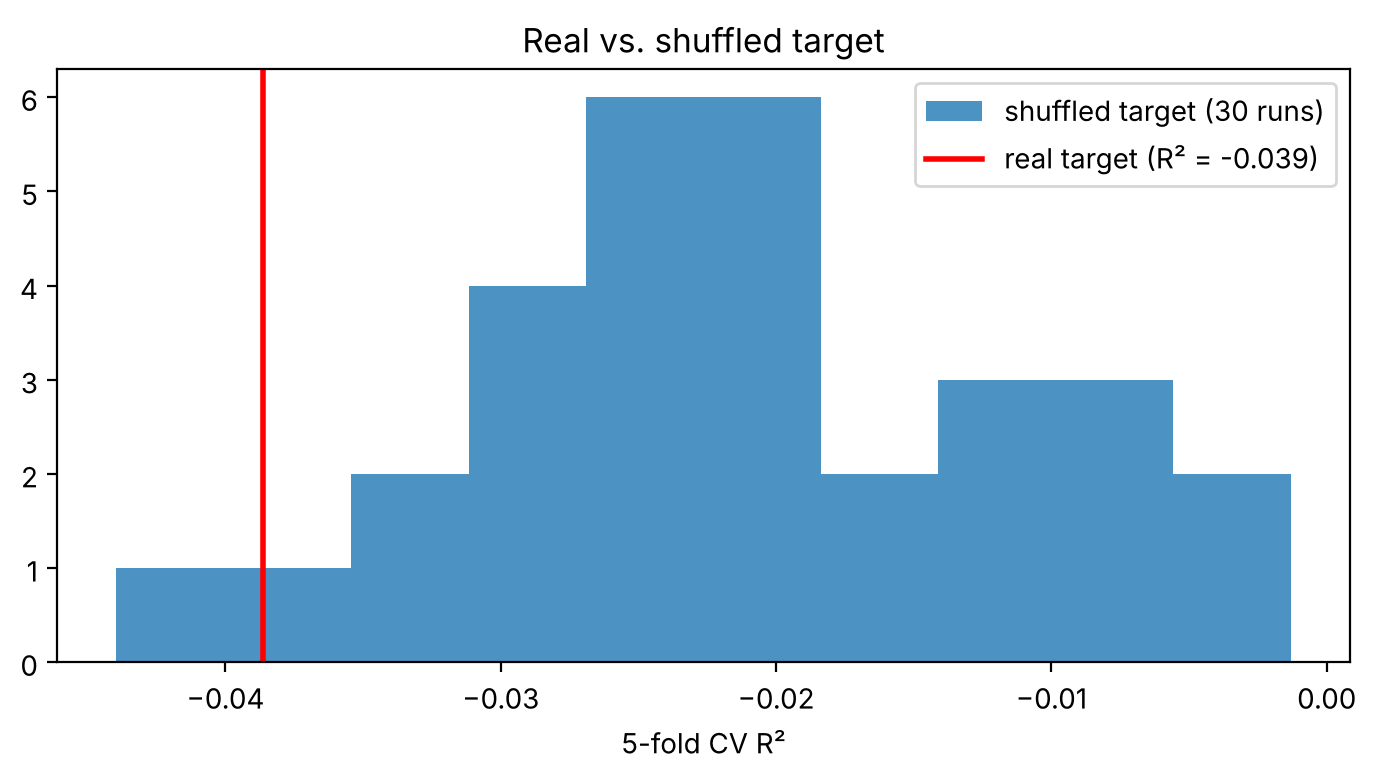

real: -0.0386 | shuffled: mean -0.0211, range [-0.0440, -0.0013]
Share of shuffled runs scoring at least as high as the real one: 0.97


In [9]:
rf = Pipeline([("prep", preprocess), ("model", RandomForestRegressor(n_estimators=100, max_depth=4, min_samples_leaf=20, random_state=SEED, n_jobs=-1))])
cv5 = KFold(5, shuffle=True, random_state=SEED)
real = cross_val_score(rf, X, y, cv=cv5, scoring="r2").mean()
rng = np.random.default_rng(SEED)
shuffled = [cross_val_score(rf, X, rng.permutation(y.values), cv=cv5, scoring="r2").mean() for _ in range(30)]

plt.figure(figsize=(7, 4)); plt.hist(shuffled, bins=10, alpha=.8, label="shuffled target (30 runs)")
plt.axvline(real, color="r", lw=2, label=f"real target (R² = {real:.3f})")
plt.xlabel("5-fold CV R²"); plt.legend(); plt.title("Real vs. shuffled target"); plt.tight_layout()
plt.savefig("figures/label_shuffle.png", dpi=200); plt.show()
print(f"real: {real:.4f} | shuffled: mean {np.mean(shuffled):.4f}, range [{min(shuffled):.4f}, {max(shuffled):.4f}]")
print("Share of shuffled runs scoring at least as high as the real one:", round(np.mean(np.array(shuffled) >= real), 2))

## 8. Conclusions
- **No model reliably beats the baseline.** Test R² ranges from −0.84 to +0.01 and cross-validated R² is ≤ 0 for all models. Ridge/Linear Regression are marginally above the mean predictor on the test set (+0.007 to +0.012) but not in cross-validation, so this is noise. The unrestricted Decision Tree is the worst (R² ≈ −0.84) because it memorises noise.
- **There is (almost) no signal to find.** Correlations with the price are all |r| < 0.08, three of four categorical features show no price differences, mutual information is tiny, and the real-target model scores no better than models trained on a shuffled target (real CV R² = −0.039 vs. −0.021 on average for shuffled).
- **Likely cause:** the dataset is synthetic with an independently generated price (uniform-looking distributions everywhere, no link between age/mileage/power and price – unlike real used-car markets where age and mileage are the dominant drivers).
- **What this project demonstrates:** a correct pipeline (no leakage, CV, tuning) *and* the discipline of testing against a naive baseline and of diagnosing a negative result instead of reporting a model that merely looks sophisticated. On real data (e.g. a scraped used-car listing set) the same notebook would be the starting point for meaningful modelling.